# KulitKu — Eksperimen CNN beku × classifier ML
## Satu notebook, satu konfigurasi, implementasi dari src

Urutan: **Setup → EDA → Cleaning → EDA lagi → Split → Fitur CNN → CV classifier → Evaluasi validation → Benchmark/pilih → Test final → ONNX**.

Tidak ada fungsi penelitian yang disalin ke notebook. Semua tahap mengimpor `kulitku_ml` dari `src`. `experiment.json` dibaca dan digunakan langsung; run_config.json di Drive adalah salinan aktual, bukan konfigurasi kedua untuk diedit. Grafik dan tabel langsung disimpan saat dibuat.

**PENTING tentang dataset augmentasi:** default `exploratory_hash` bisa dipakai mencoba pipeline tanpa identitas gambar asal, tetapi hanya menahan duplikat byte persis. Variasi crop/rotasi/flip atau foto pasien sama belum tentu berada dalam kelompok yang sama. Semua hasil diberi status EKSPLORATORI dan tidak membuktikan generalisasi klinis. Untuk eksperimen final, gunakan `verified_groups` dan CSV lineage berisi bukti; contoh CSV dan petunjuk ada di configs/ dan README.

Tidak ada data, weights medis atau hasil akurasi penelitian yang disertakan. Pretrained weights diunduh saat ekstraksi pertama. GPU T4 membantu ekstraksi; classifier sklearn berjalan di CPU. Colab gratis mungkin membutuhkan beberapa sesi.


## 1. Persiapkan kode di Colab
**Cara ZIP (tanpa harus membuat GitHub dahulu):** ekstrak ZIP di laptop, upload notebook ini ke Colab, lalu jalankan sel berikut. Saat diminta, upload ZIP paket utuh ke runtime Colab (bukan dataset). Kode mengekstrak folder KulitKu di /content.

**Cara GitHub:** upload isi folder KulitKu ke repository-mu, isi REPO_URL dan REPO_REF. Untuk repo private gunakan ZIP agar tidak perlu menaruh token pada notebook. Sel tidak menimpa checkout yang sudah ada; kode lokal harus sama dengan ref yang dimaksud.

Tidak mengimpor ML library sebelum instalasi agar mengurangi modul versi lama di memori.


In [2]:
from pathlib import Path
import os,sys,subprocess,zipfile,json
REPO_URL = 'https://github.com/Liex2810/KulitKu.git'   # opsional URL HTTPS github.com tanpa token; kosong = upload ZIP
REPO_REF = 'main'
CODE_ROOT = Path('/content/KulitKu/machine-learning')
if not (CODE_ROOT/'pyproject.toml').exists():
    if REPO_URL:
        from urllib.parse import urlparse
        parsed=urlparse(REPO_URL)
        if parsed.scheme!='https' or parsed.hostname!='github.com' or parsed.username or parsed.password:
            raise ValueError('Gunakan URL GitHub HTTPS tanpa kredensial.')
        target=Path('/content/KulitKu')
        if target.exists():raise FileExistsError('Direktori kode sudah ada, periksa isinya tanpa menghapus pekerjaan.')
        subprocess.run(['git','clone','--branch',REPO_REF,REPO_URL,str(target)],check=True)
    else:
        from google.colab import files
        print('Upload ZIP paket KulitKu lengkap, bukan ZIP dataset.')
        uploaded=files.upload()
        candidates=[Path(n) for n in uploaded if n.lower().endswith('.zip')]
        if len(candidates)!=1:raise ValueError('Upload tepat satu ZIP paket.')
        with zipfile.ZipFile(candidates[0]) as archive:
            dest=Path('/content').resolve()
            for item in archive.infolist():
                resolved=(dest/item.filename).resolve()
                if not resolved.is_relative_to(dest):raise ValueError('Path ZIP tidak aman.')
                if ((item.external_attr>>16)&0o170000)==0o120000:raise ValueError('Symlink ZIP tidak diizinkan.')
            archive.extractall(dest)
if not (CODE_ROOT/'src/kulitku_ml/config.py').exists():raise FileNotFoundError('Struktur kode tidak sesuai; harus /content/KulitKu/machine-learning.')
print('Kode:',CODE_ROOT)


Kode: /content/KulitKu/machine-learning


## 2. Instal dependensi
Pasangan torch/torchvision CUDA bawaan Colab digunakan bila memenuhi versi yang dibutuhkan. pandas/Pillow tidak dipaksa ke versi yang bertentangan dengan Colab. requirements memakai pin untuk komponen model/ONNX dan rentang untuk library bawaan; versi aktual direkam di environment.json.

Jika Colab meminta restart, restart session lalu jalankan bagian 1, lewati instalasi yang sudah selesai dengan INSTALL_DEPENDENCIES=False, dan lanjut bagian 3. Jangan mencampur versi dalam satu run.


In [3]:
INSTALL_DEPENDENCIES = True
if INSTALL_DEPENDENCIES:
    subprocess.run([sys.executable,'-m','pip','install','-r',str(CODE_ROOT/'requirements.txt')],check=True)
    subprocess.run([sys.executable,'-m','pip','install','--no-deps','-e',str(CODE_ROOT)],check=True)
check=subprocess.run([sys.executable,'-m','pip','check'],capture_output=True,text=True)
print(check.stdout or check.stderr)
if check.returncode:
    raise RuntimeError('Konflik paket terdeteksi. Selesaikan sebelum menjalankan eksperimen; jangan menonaktifkan pemeriksaan.')


No broken requirements found.



## 3. Mount Drive dan baca satu konfigurasi
Sesuaikan path dalam `configs/experiment.json` sebelum menjalankan, atau isi dua override path di bawah. Override dicatat di salinan run_config.json. Pengaturan model/grid/fold tetap dibaca dari JSON, bukan digandakan dalam sel.

RUN_ID kosong membuat eksperimen baru. Untuk melanjutkan sesi terputus, isi RUN_ID yang tercetak/disimpan; kode/config/versi paket harus sama dan dataset tidak berubah. Cache tersedia per CNN dan per kandidat/fold classifier yang selesai. Batch fitur CNN yang belum selesai harus diulang.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, sys, subprocess, shutil
import torch
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(CODE_ROOT / 'src'))
from kulitku_ml.config import load_config, Run

cfg = load_config(CODE_ROOT / 'configs/experiment.json')

# Folder dataset lengkap.
SOURCE_ROOT = Path(
    '/content/drive/MyDrive/KulitKu/datasets/original'
)

# Folder baru khusus file tanpa awalan aug_.
# Gunakan nama folder baru jika folder ini sudah pernah dibuat.
FILTERED_ROOT = Path(
    '/content/drive/MyDrive/KulitKu/datasets/non_aug_v1'
)

if not SOURCE_ROOT.is_dir():
    raise FileNotFoundError(f'Dataset tidak ditemukan: {SOURCE_ROOT}')

# Mencegah tercampur dengan hasil penyaringan sebelumnya.
if FILTERED_ROOT.exists():
    raise FileExistsError(
        f'{FILTERED_ROOT} sudah ada. '
        'Gunakan nama baru, misalnya non_aug_v2.'
    )

extensions = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.webp', '.tif', '.tiff'
}

# Inventaris dahulu sebelum membuat folder tujuan.
selected = []
counts = []

for label in cfg['classes']:
    class_dir = SOURCE_ROOT / label

    if not class_dir.is_dir():
        raise FileNotFoundError(f'Folder kelas tidak ada: {class_dir}')

    images = sorted(
        p for p in class_dir.rglob('*')
        if p.is_file() and p.suffix.lower() in extensions
    )

    kept = [
        p for p in images
        if not p.name.lower().startswith('aug_')
    ]

    if not kept:
        raise ValueError(f'Tidak ada gambar non-aug pada kelas {label}')

    selected.extend(kept)
    counts.append({
        'kelas': label,
        'total': len(images),
        'tanpa_awalan_aug': len(kept),
        'dilewati_aug': len(images) - len(kept),
    })

display(pd.DataFrame(counts))

FILTERED_ROOT.mkdir(parents=True)

for i, source in enumerate(selected, start=1):
    destination = FILTERED_ROOT / source.relative_to(SOURCE_ROOT)
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)

    if i % 200 == 0 or i == len(selected):
        print(f'Disalin: {i}/{len(selected)}')

# Gunakan hasil penyaringan untuk run baru.
cfg['paths']['dataset_root'] = str(FILTERED_ROOT)

OUTPUT_ROOT_OVERRIDE = ''
if OUTPUT_ROOT_OVERRIDE:
    cfg['paths']['output_root'] = OUTPUT_ROOT_OVERRIDE

os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

# Jangan memakai RUN_ID lama karena dataset berubah.
RUN_ID = ''
run = Run(cfg, RUN_ID or None)

print('RUN_ID:', run.id)
print('Data:', run.root)
print('Hasil:', run.out)
print(
    'GPU:',
    torch.cuda.get_device_name(0)
    if torch.cuda.is_available() else 'CPU'
)
print('Mode split:', cfg['split']['mode'])

if run.exploratory:
    print(
        'HASIL EKSPLORATORI: hubungan foto asal/pasien '
        'belum terverifikasi.'
    )

freeze = subprocess.run(
    [sys.executable, '-m', 'pip', 'freeze'],
    capture_output=True,
    text=True,
    check=True
).stdout

safe_lines = [
    line for line in freeze.splitlines()
    if '://' not in line
    and ' @ ' not in line
    and not line.startswith('-e ')
]

(run.out / 'requirements_snapshot.txt').write_text(
    '\n'.join(safe_lines) + '\n'
)

Mounted at /content/drive


,kelas,total,tanpa_awalan_aug,dilewati_aug
0,Eczema,6715,1544,5171
1,Herpes Zoster,8082,163,7919
2,Normal,7773,170,7603
3,Ringworm,8129,113,8016


Disalin: 200/1990
Disalin: 400/1990
Disalin: 600/1990
Disalin: 800/1990
Disalin: 1000/1990
Disalin: 1200/1990
Disalin: 1400/1990
Disalin: 1600/1990
Disalin: 1800/1990
Disalin: 1990/1990
RUN_ID: 20261106T094748_099960Z
Data: /content/drive/MyDrive/KulitKu/datasets/non_aug_v1
Hasil: /content/drive/MyDrive/KulitKu/hasil/20261106T094748_099960Z
GPU: CPU
Mode split: exploratory_hash
HASIL EKSPLORATORI: hubungan foto asal/pasien belum terverifikasi.


11959

## 4. Inventaris dan EDA awal
Sel ini membaca setiap file untuk decode, format dan resolusi; hash belum dihitung. Jika data masih di Drive, I/O bisa lambat. Boleh arahkan dataset_root ke salinan lokal Colab dari dataset yang sama; pastikan salinan memang lengkap dan jangan mengubah sumber dalam satu run. Mengganti path mengharuskan run baru.

Tabel, grafik resolusi/format/kelas, galeri dan indikator visual sampel langsung disimpan ke Drive. Indikator brightness/Laplacian tidak menjadi alasan eksklusi otomatis.


Daftar file: Eczema
Daftar file: Herpes Zoster
Daftar file: Normal
Daftar file: Ringworm


Baca gambar; tanpa hash:   0%|          | 0/1990 [00:00<?, ?it/s]

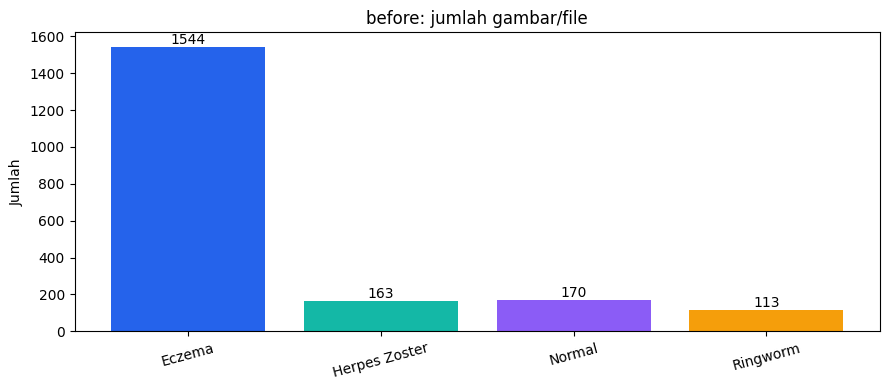

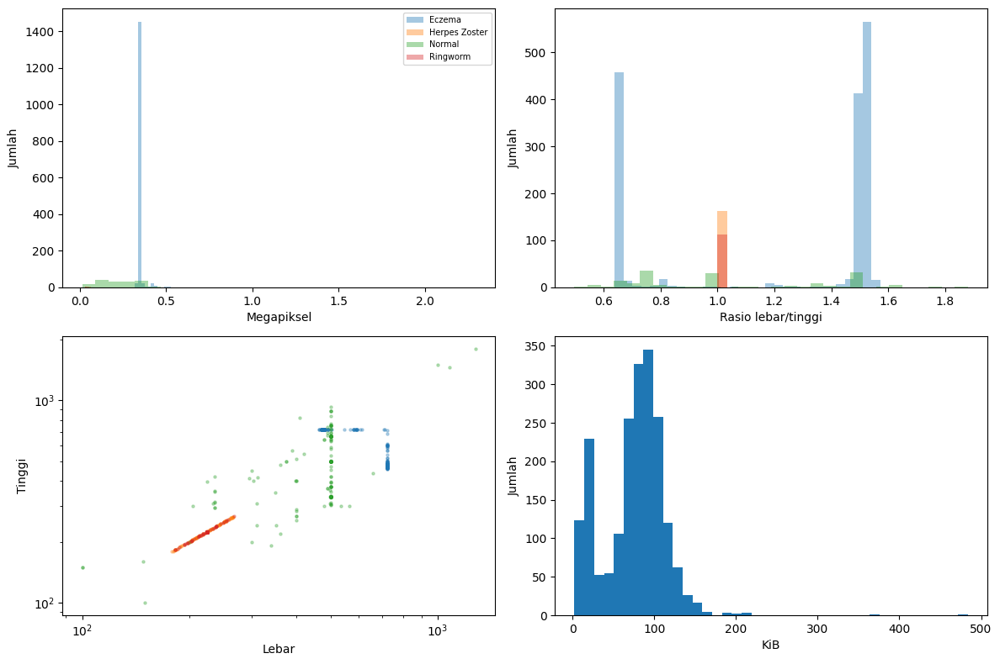

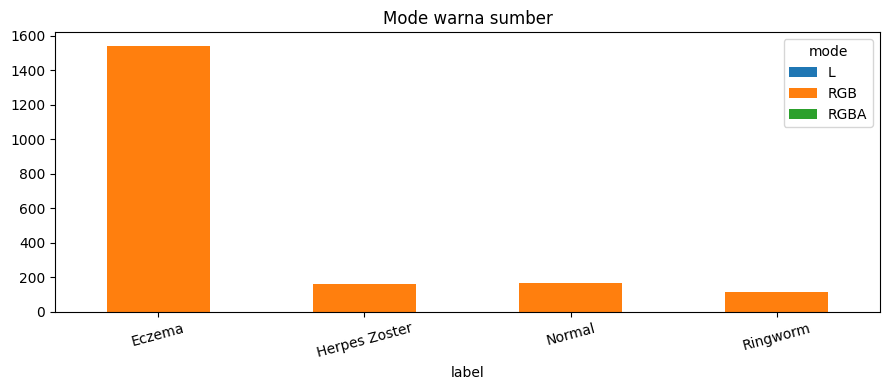

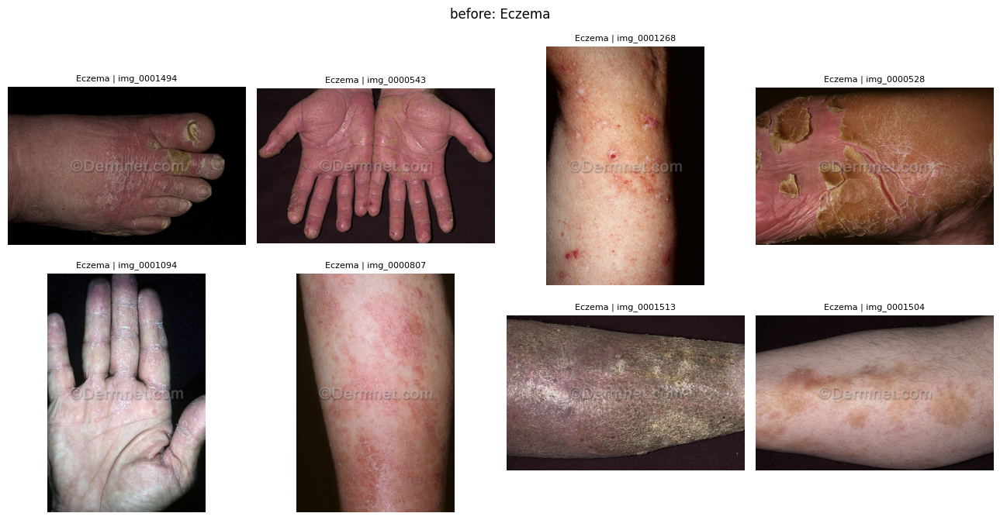

EDA sampel Eczema:   0%|          | 0/200 [00:00<?, ?it/s]

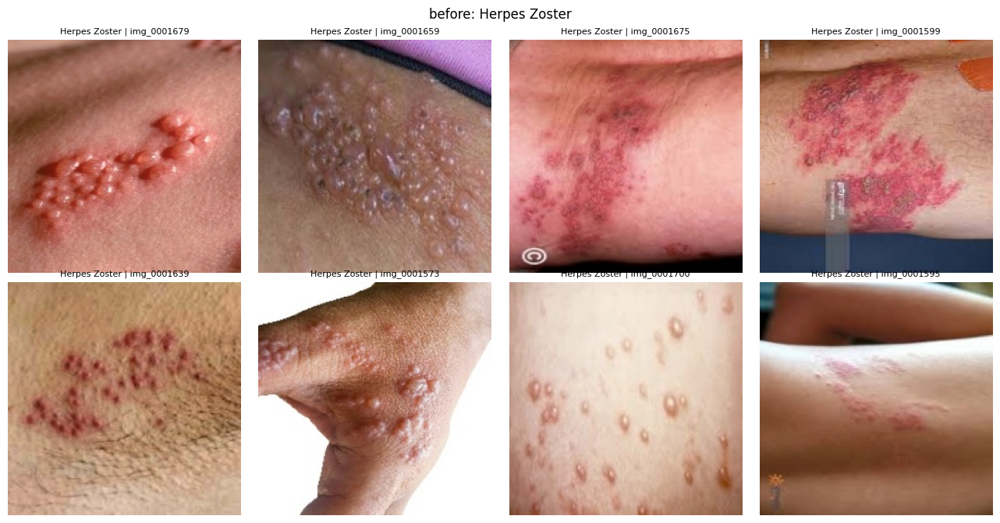

EDA sampel Herpes Zoster:   0%|          | 0/163 [00:00<?, ?it/s]

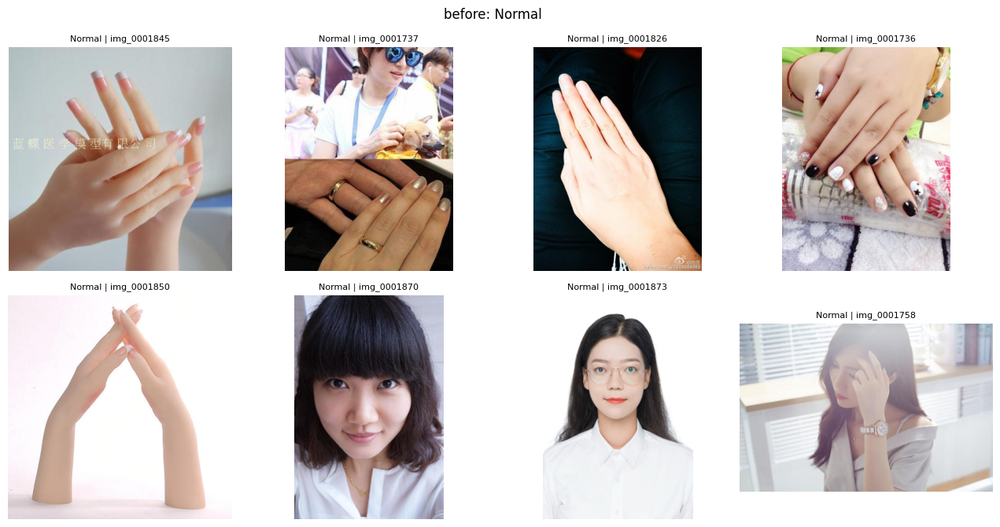

EDA sampel Normal:   0%|          | 0/169 [00:00<?, ?it/s]

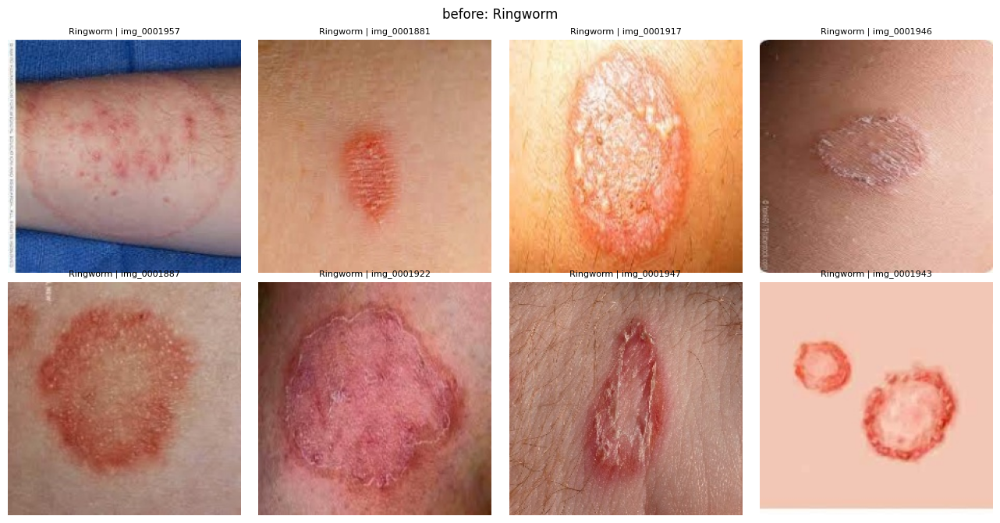

EDA sampel Ringworm:   0%|          | 0/113 [00:00<?, ?it/s]

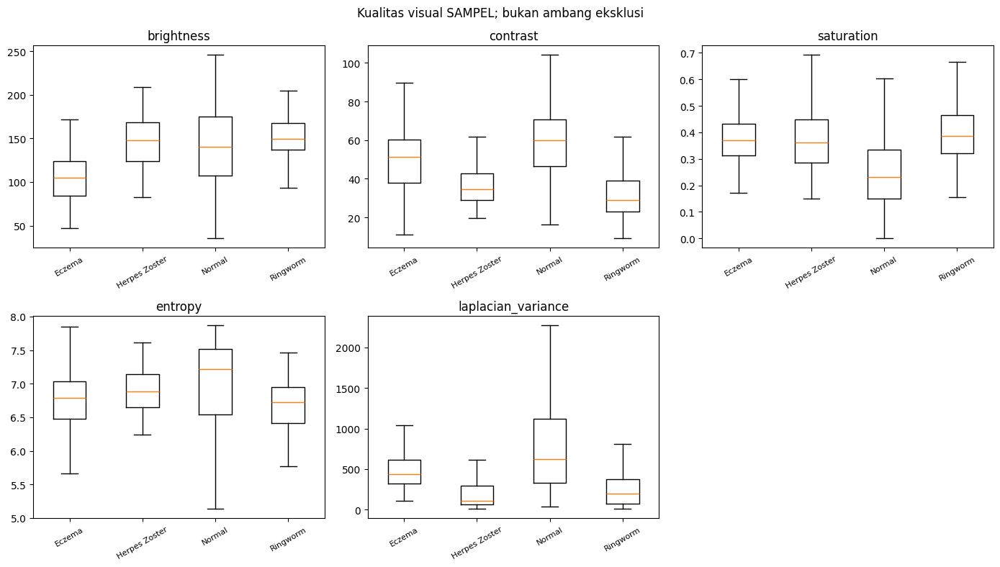

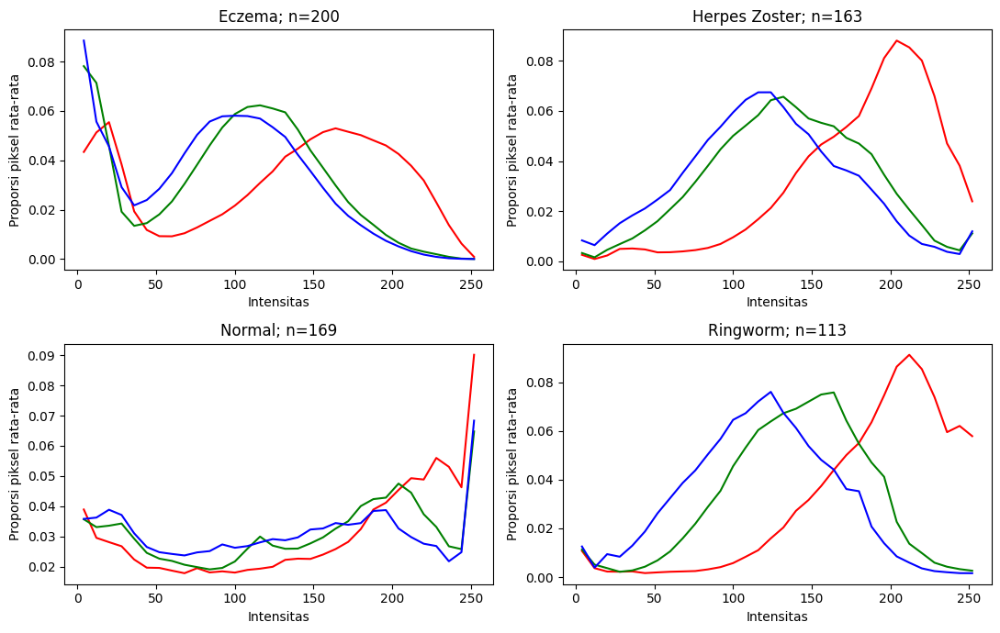

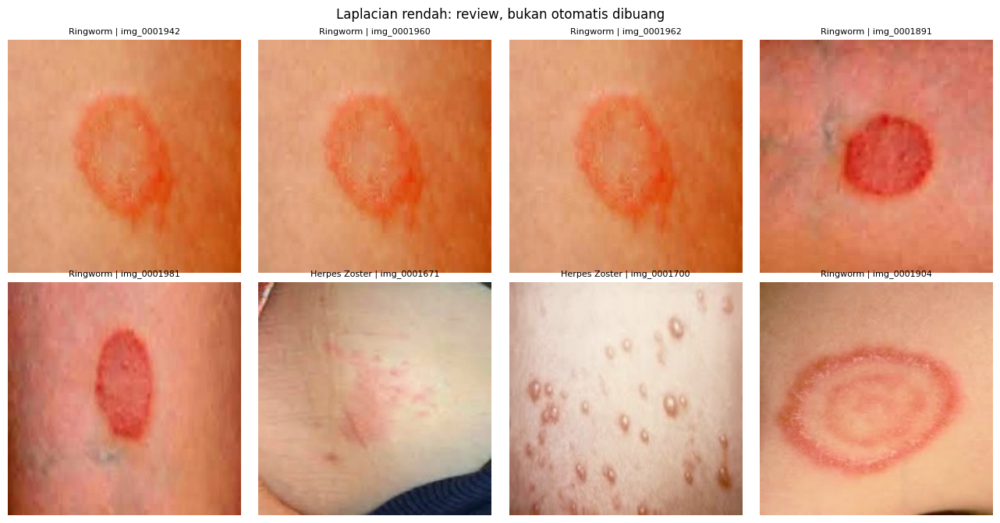

,label,n,percent
0,Eczema,1544,77.587940
1,Herpes Zoster,163,8.190955
2,Normal,170,8.542714
3,Ringworm,113,5.678392


In [5]:
from kulitku_ml.data import inventory
from kulitku_ml.eda import eda,compare
before=inventory(run)
display(eda(run,before,'before'))


## 5. Cleaning dan EDA setelah cleaning
Cleaning teknis tidak menghapus sumber. Review manual opsional memakai tabel/manual_review_template.csv. Untuk menerapkannya, isi path cleaning.manual_review_csv pada konfigurasi lalu buat run baru, agar keputusan lama tidak tercampur.

Output cleaned.csv adalah daftar kandidat; tidak menyalin seluruh foto dan belum menjamin bebas duplikat. Mode grayscale/alpha yang bisa dikonversi RGB tetap dipertahankan. Minimum 128px default hanya flag. Transformasi input CNN belum dilakukan; diterapkan saat ekstraksi.


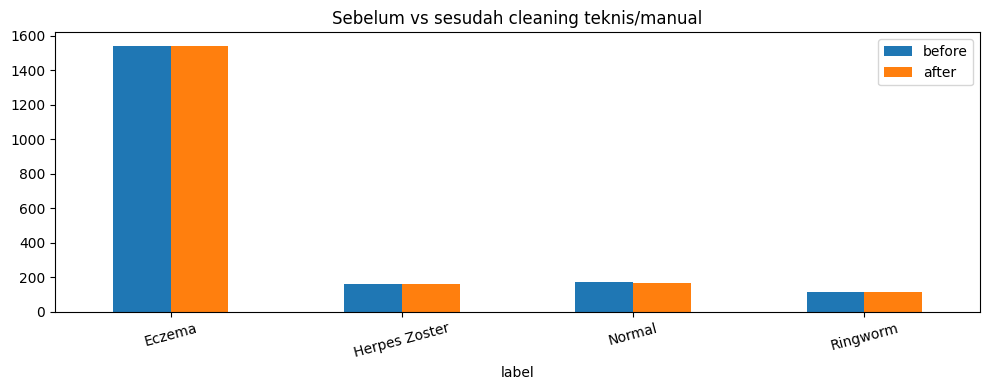

,label,before,after
0,Eczema,1544,1544
1,Herpes Zoster,163,163
2,Normal,170,169
3,Ringworm,113,113


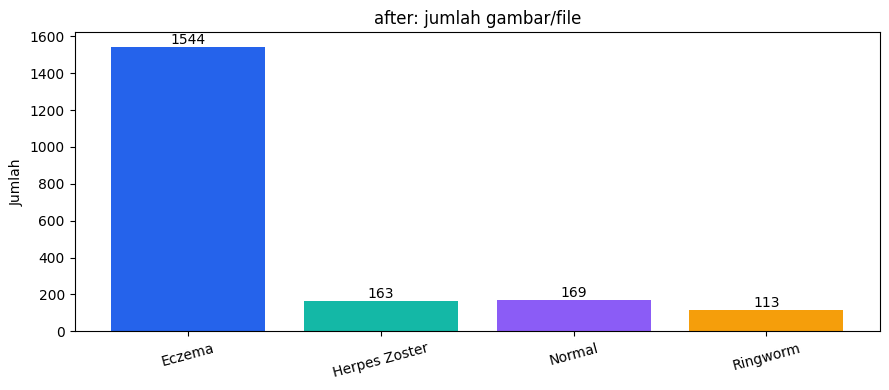

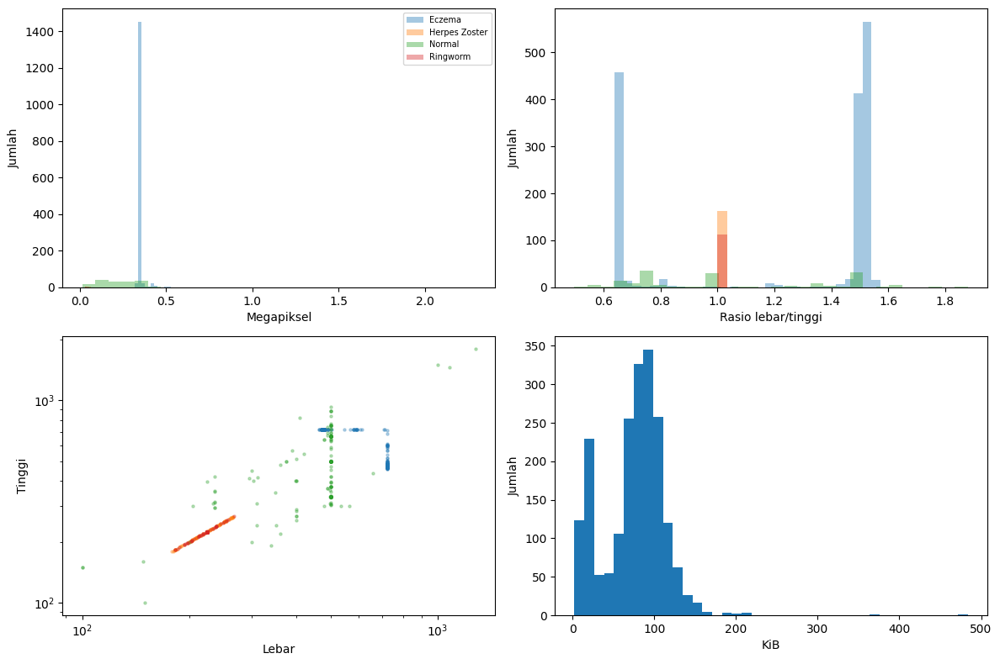

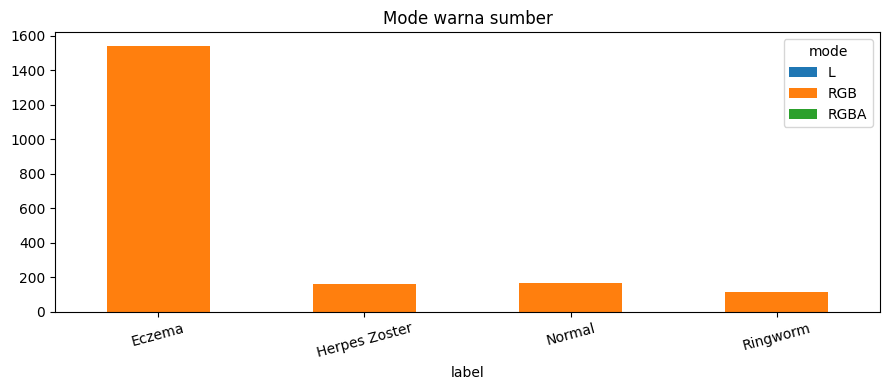

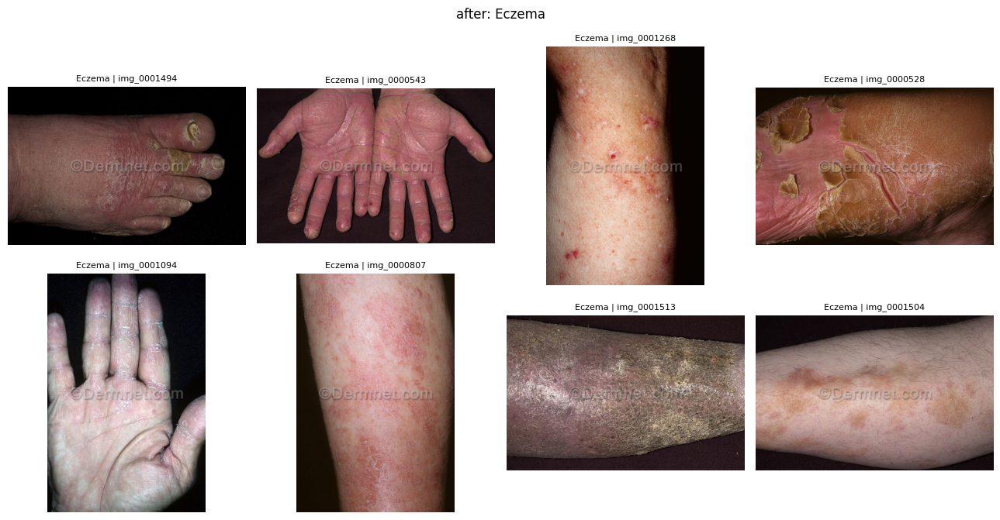

EDA sampel Eczema:   0%|          | 0/200 [00:00<?, ?it/s]

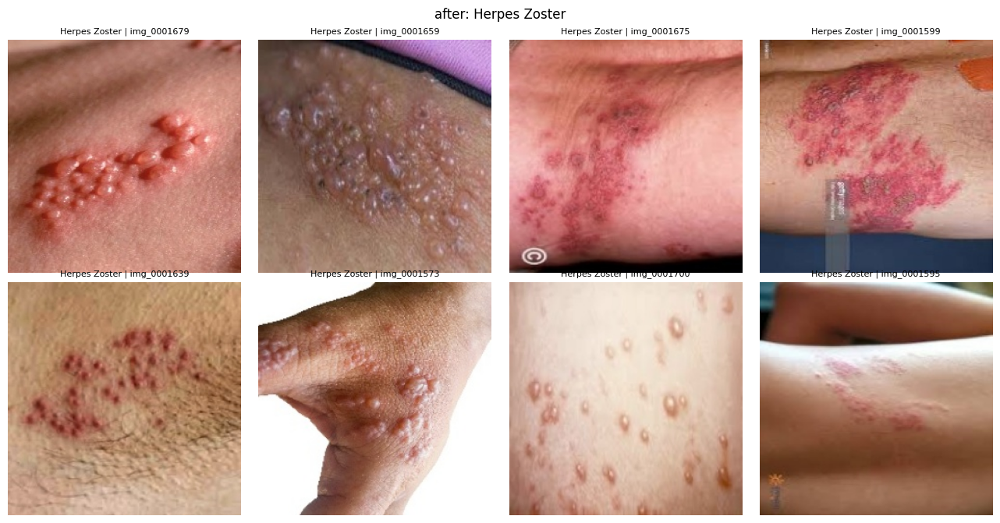

EDA sampel Herpes Zoster:   0%|          | 0/163 [00:00<?, ?it/s]

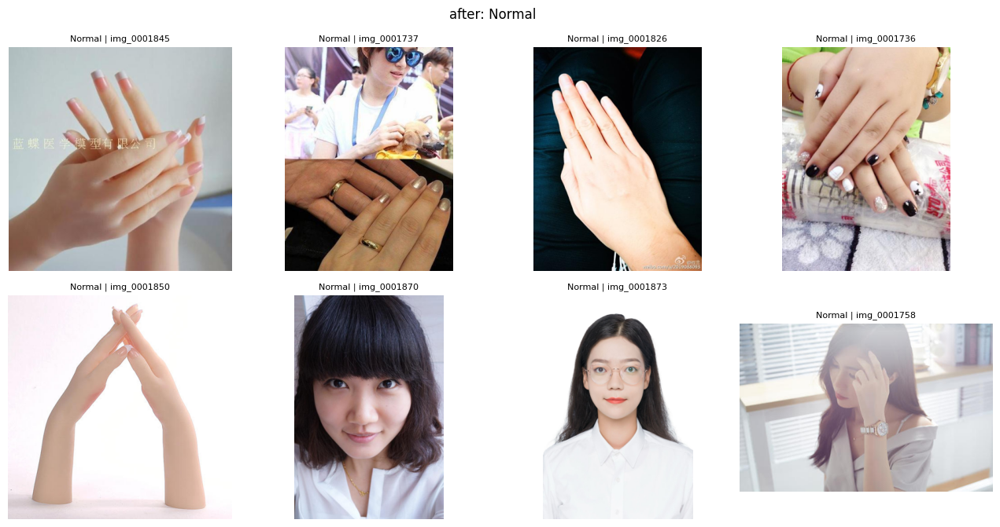

EDA sampel Normal:   0%|          | 0/169 [00:00<?, ?it/s]

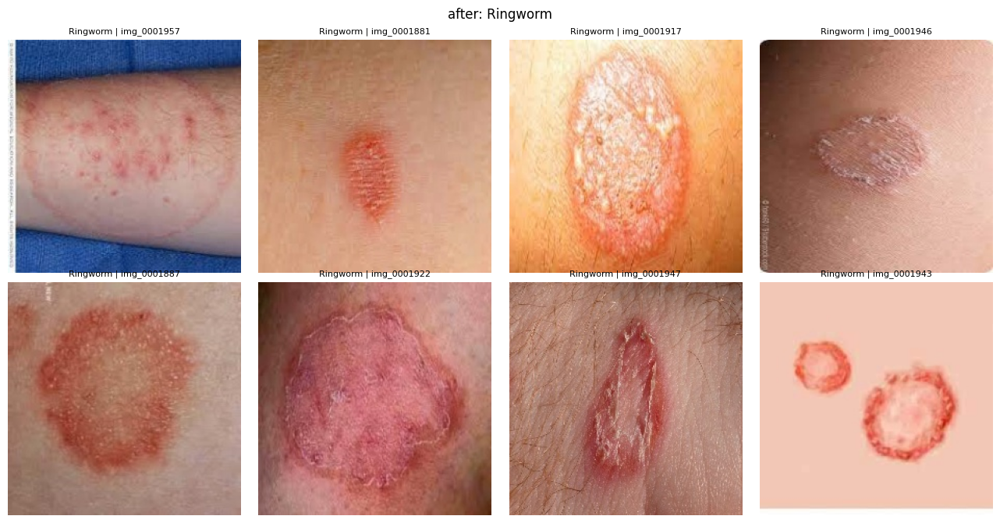

EDA sampel Ringworm:   0%|          | 0/113 [00:00<?, ?it/s]

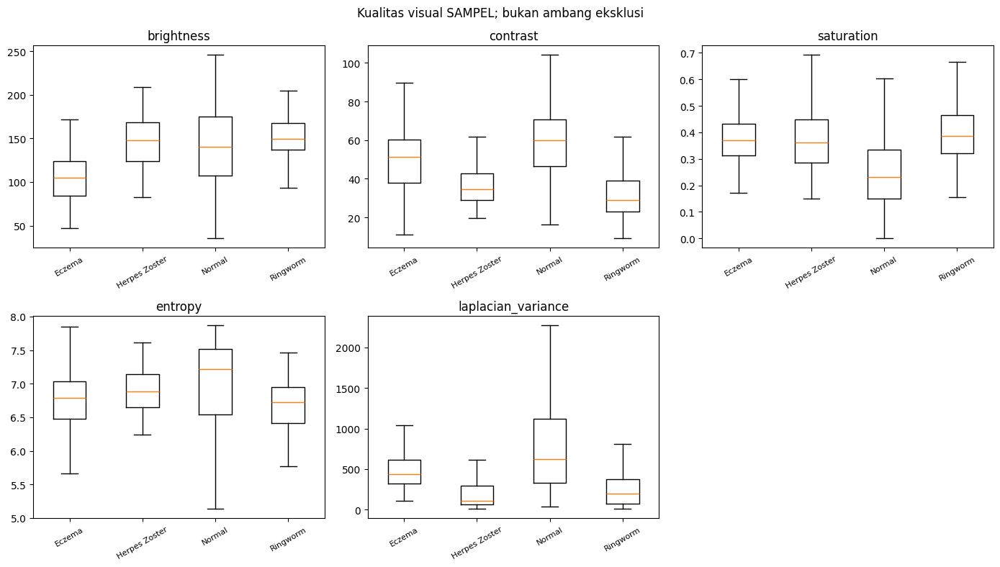

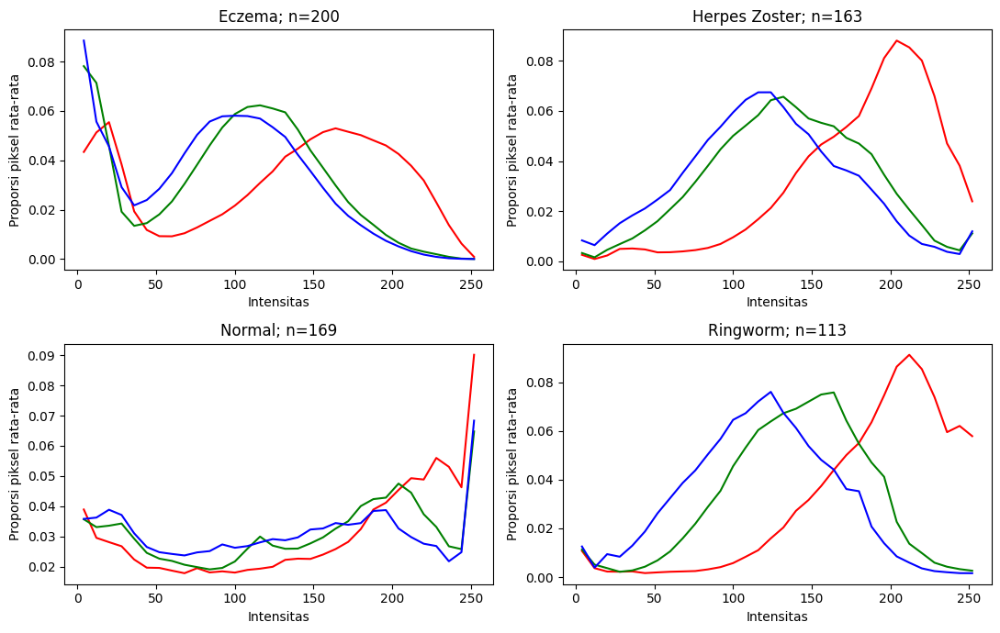

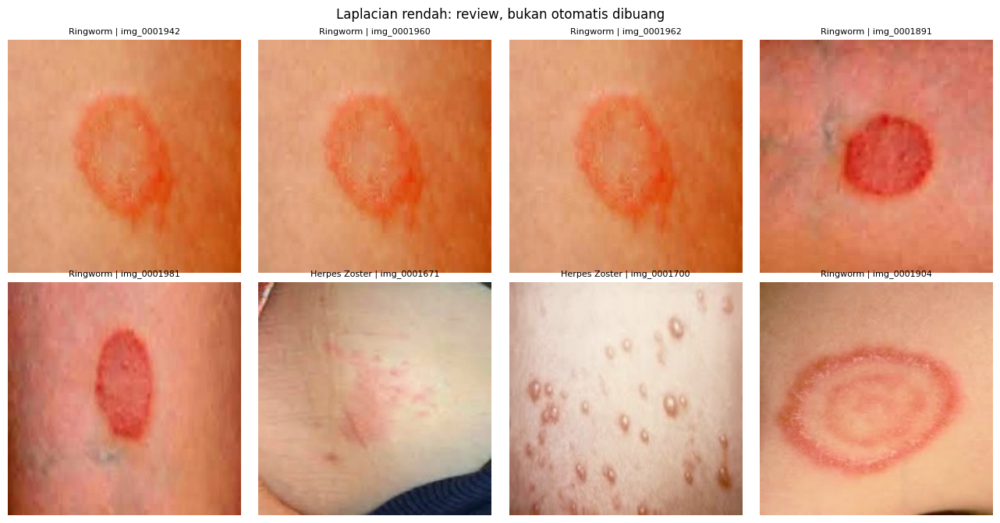

,label,n,percent
0,Eczema,1544,77.626948
1,Herpes Zoster,163,8.195073
2,Normal,169,8.496732
3,Ringworm,113,5.681247


Kandidat setelah cleaning: 1989


In [6]:
from kulitku_ml.cleaning import clean
after=clean(run,before)
display(compare(run,before,after))
display(eda(run,after,'after'))
print('Kandidat setelah cleaning:',len(after))


## 6. Split development/test dan lima fold
Hash byte dilakukan pada tahap ini untuk exact duplicate, bukan pada EDA. Konflik label duplikat harus diselesaikan melalui review; proses berhenti dengan tabel yang menunjukkan konflik, tidak menebak label yang benar.

Default: holdout 1 dari 5 kelompok (~20% test) dan lima fold development. `verified_groups` memakai kelompok asal ber-bukti, validation/test original terverifikasi, turunannya hanya training kelompok terkait. Default `exploratory_hash` hanya menahan exact duplicate dan tetap berisiko kebocoran augmentasi. Tidak ada klaim split antar pasien karena patient_id tidak tersedia.


In [7]:
from kulitku_ml.splitting import split
splits=split(run,after)
display(run.read('split_summary.csv'))


Hash dilakukan sekali pada tahap split, bukan pada EDA.


Hash untuk exact duplicate:   0%|          | 0/1989 [00:00<?, ?it/s]

PERINGATAN: eksperimen eksploratori. SHA hanya mencegah duplikat byte melintasi split; variasi augmentasi/pasien belum terpisah.


,partition,label,fold,evaluation_eligible,n
0,development,Eczema,0,True,231
1,development,Eczema,1,True,231
2,development,Eczema,2,True,230
3,development,Eczema,3,True,230
4,development,Eczema,4,True,230
5,development,Herpes Zoster,0,True,25
6,development,Herpes Zoster,1,True,25
7,development,Herpes Zoster,2,True,26
8,development,Herpes Zoster,3,True,26
9,development,Herpes Zoster,4,True,26


## 7. Ekstraksi tiga CNN beku
Seluruh bobot tidak di-update; mode eval. CNN menghasilkan vektor fitur sebelum kepala klasifikasi. Ini menghemat komputasi dan membuat perbandingan fitur lebih jelas. Classifier yang dilatih menggunakan label KulitKu, bukan CNN-nya.

Pretrained weights timm diunduh pertama kali. Preprocessing spesifik weights disimpan dan digunakan ulang. Fitur seluruh gambar dapat di-cache karena ekstraktor beku/deterministik; tidak ada scaler atau komponen terlatih yang di-fit menggunakan test. Cache tidak digunakan jika urutan split berubah.

Jalankan satu CNN dahulu jika perlu; semua nama diambil dari JSON. TRAIN_ONLY_CNN/CLASSIFIER pada tahap berikut hanya filter eksekusi, bukan perubahan protokol/grid.


In [8]:
from kulitku_ml.features import extract_features
EXTRACT_ONLY = ''  # kosong=semua; atau mobilenetv4 / resnet50 / convnext_tiny
for cnn in cfg['extractors']:
    if EXTRACT_ONLY and cnn!=EXTRACT_ONLY:continue
    x=extract_features(run,splits,cnn)
    print(cnn,x.shape)


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Fitur mobilenetv4:   0%|          | 0/59 [00:00<?, ?it/s]

mobilenetv4 (1880, 1280)


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Fitur convnext_tiny:   0%|          | 0/59 [00:00<?, ?it/s]

convnext_tiny (1880, 768)


## 8. Training tiga classifier dan 5-fold CV
Setiap CNN × LR/SVM/RF menghasilkan sembilan kombinasi. Scaler LR/SVM di-fit hanya pada training setiap fold. RF tanpa scaler. Grid default 26 kandidat per CNN × 5 fold = 390 fit pencarian, ditambah refit dan pembuatan prediksi validation terpilih. Bisa lama pada Colab gratis.

Model terbaik tiap kombinasi di-refit pada seluruh development untuk benchmarking; test tidak dilihat. Progress disimpan setiap kandidat/fold sehingga run yang sama dapat dilanjutkan. Jangan load joblib dari sumber tak dipercaya.


In [31]:
import copy
import shutil
from datetime import datetime

import numpy as np
from kulitku_ml.training import train_classifier

CNN = 'convnext_tiny'
CLASSIFIER = 'random_forest'

# Periksa fitur sebelum mengubah konfigurasi.
x = np.load(
    run.out / 'features' / CNN / 'features.npy',
    mmap_mode='r',
)

if len(x) != len(splits):
    raise ValueError('Jumlah baris fitur dan splits berbeda.')

# Siapkan grid balanced pada konfigurasi yang dibaca training.
new_grid = copy.deepcopy(run.c['classifiers'][CLASSIFIER])
new_grid['model__class_weight'] = ['balanced']

stamp = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
model_folder = run.out / 'models' / CNN / CLASSIFIER

if new_grid != run.c['classifiers'][CLASSIFIER]:
    # Simpan konfigurasi sebelumnya.
    run.json(
        copy.deepcopy(run.c),
        f'config_before_balanced_{stamp}.json',
    )

    # Grid berubah: cache lama harus dipisahkan.
    # Hasil lama diarsipkan, bukan dihapus.
    if model_folder.exists():
        archive = (
            run.out / 'archive' / stamp
            / 'models' / CNN / CLASSIFIER
        )
        archive.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(model_folder), str(archive))
        print('Cache lama diarsipkan:', archive)

    run.c['classifiers'][CLASSIFIER] = new_grid
    run.json(run.c, 'run_config.json')

# Samakan cfg agar tidak membingungkan.
cfg['classifiers'][CLASSIFIER] = copy.deepcopy(new_grid)

print('RUN_ID:', run.id)
print('Bobot:', run.c['classifiers'][CLASSIFIER]['model__class_weight'])

# Training dengan bobot otomatis dari training setiap fold.
result = train_classifier(
    run, splits, x, CNN, CLASSIFIER
)

print(result['combo_id'], result['mean_macro_f1'])

RUN_ID: 20261106T094748_099960Z
Bobot: ['balanced']
convnext_tiny/random_forest kandidat 1/4 fold 1/5
convnext_tiny/random_forest kandidat 1/4 fold 2/5
convnext_tiny/random_forest kandidat 1/4 fold 3/5
convnext_tiny/random_forest kandidat 1/4 fold 4/5
convnext_tiny/random_forest kandidat 1/4 fold 5/5
convnext_tiny/random_forest kandidat 2/4 fold 1/5
convnext_tiny/random_forest kandidat 2/4 fold 2/5
convnext_tiny/random_forest kandidat 2/4 fold 3/5
convnext_tiny/random_forest kandidat 2/4 fold 4/5
convnext_tiny/random_forest kandidat 2/4 fold 5/5
convnext_tiny/random_forest kandidat 3/4 fold 1/5
convnext_tiny/random_forest kandidat 3/4 fold 2/5
convnext_tiny/random_forest kandidat 3/4 fold 3/5
convnext_tiny/random_forest kandidat 3/4 fold 4/5
convnext_tiny/random_forest kandidat 3/4 fold 5/5
convnext_tiny/random_forest kandidat 4/4 fold 1/5
convnext_tiny/random_forest kandidat 4/4 fold 2/5
convnext_tiny/random_forest kandidat 4/4 fold 3/5
convnext_tiny/random_forest kandidat 4/4 fold 4/

## 9. Evaluasi validation dan visualisasi sembilan kombinasi
Confusion matrix jumlah/normalisasi, precision-recall-F1 per kelas, galeri salah, heatmap 3×3, mean±SD dan skor setiap fold. Skor validation ini sudah dipakai tuning, sehingga bukan evaluasi akhir independen.


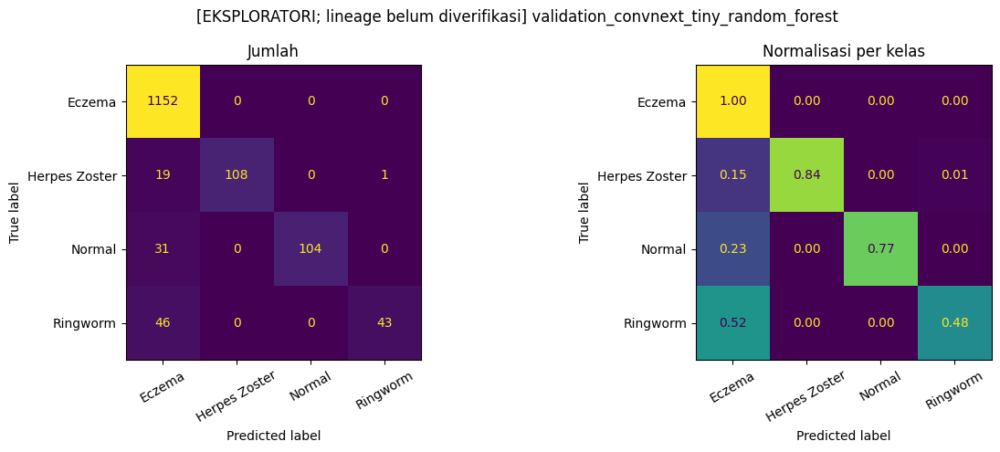

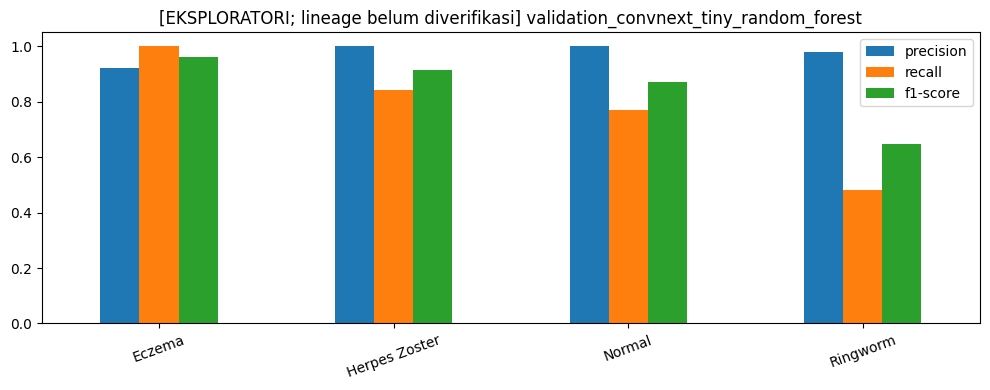

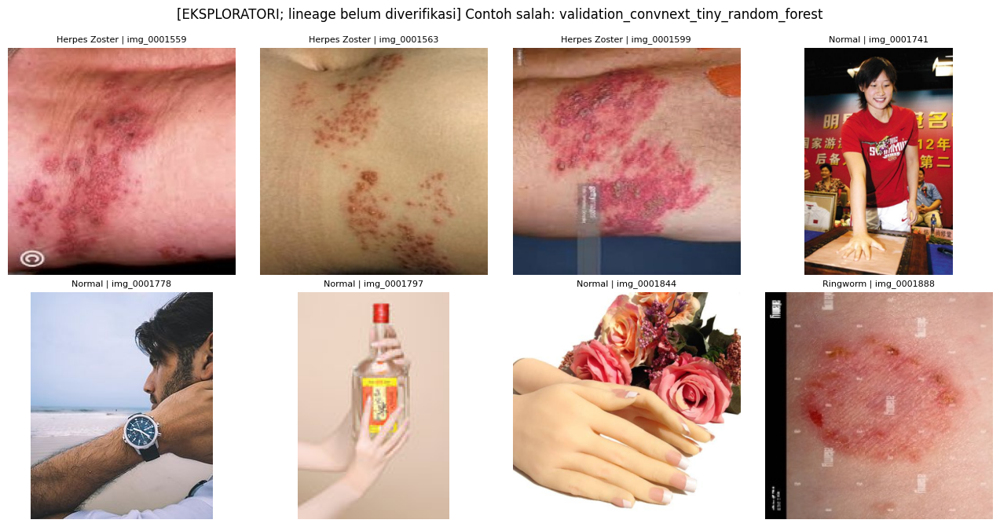

{'macro_f1': 0.8480409164177019,
 'accuracy': 0.9355053191489362,
 'macro_precision': 0.9750874125874127,
 'macro_recall': 0.7743166094465253}

In [32]:
from kulitku_ml.evaluation import validation_report

display(
    validation_report(
        run,
        "convnext_tiny",
        "random_forest",
    )
)

## Bandingkan semuanya dahulu.

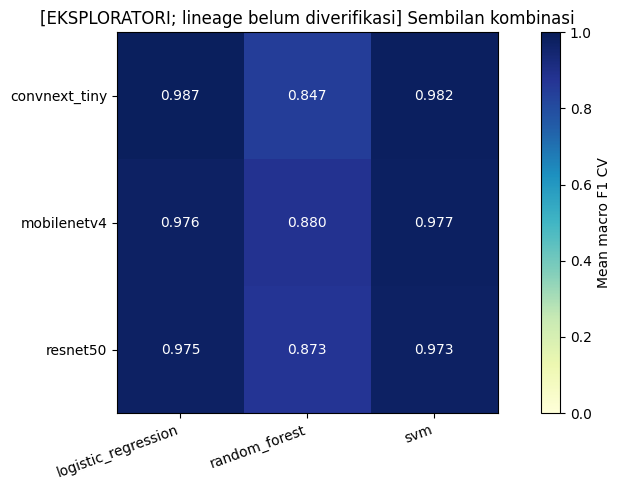

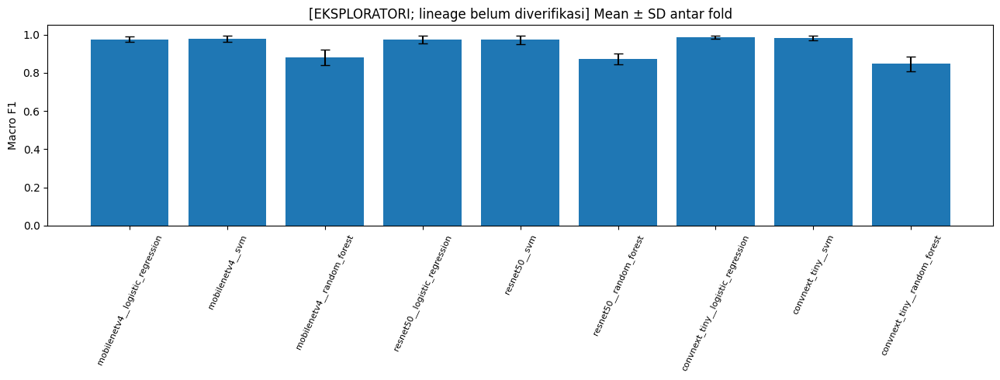

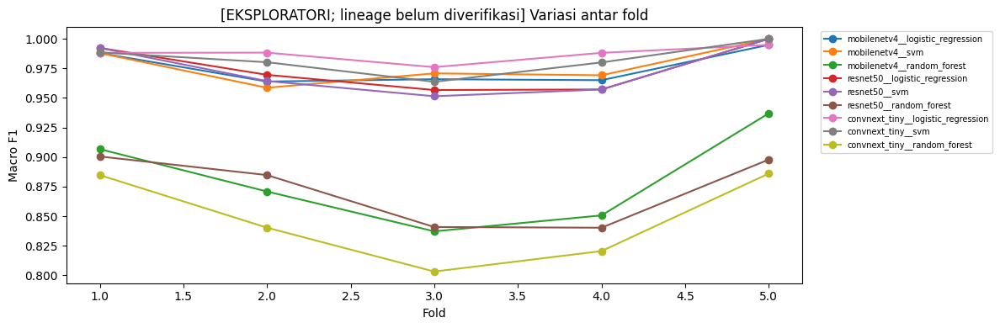

,identity,cnn,classifier,combo_id,best_params,mean_macro_f1,std_macro_f1,refit_seconds,total_search_fit_seconds,exploratory
0,0a25ac69b5188a2f8adecd22cdc1c36e10419f90cdce87...,mobilenetv4,logistic_regression,mobilenetv4__logistic_regression,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.975522,0.014748,0.651665,8.171378,True
1,72945b0c561c11d0511c8aadf638c9573fc1cd71a93c5f...,mobilenetv4,svm,mobilenetv4__svm,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.977305,0.016482,0.314759,18.847701,True
2,2443adf98a25b66f2f289cb87db220f9d371a19584a874...,mobilenetv4,random_forest,mobilenetv4__random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.880467,0.041043,6.377422,87.607722,True
3,dfcddde3e34dbaa5401b64f5dc9e92e732ffd7408ed2df...,resnet50,logistic_regression,resnet50__logistic_regression,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.975142,0.020050,1.336322,12.447775,True
4,d9f2f9db58ed3f3fa11cebec862a3dd5d30cdb8c1b572c...,resnet50,svm,resnet50__svm,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.973040,0.021759,1.018557,35.725971,True
5,5be2cad8cfb6efc7673babadee23dc5a6154e47fee933b...,resnet50,random_forest,resnet50__random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.872833,0.030093,10.395902,151.412558,True
6,c93f73753dc684be6cd828e597957a1a24a82a6ff5320c...,convnext_tiny,logistic_regression,convnext_tiny__logistic_regression,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.987108,0.006839,0.459782,7.977588,True
7,1d652d192a95787bf617398f5c485c3aa82df5d2c4768a...,convnext_tiny,svm,convnext_tiny__svm,"{'model__C': 10, 'model__class_weight': 'balan...",0.982477,0.013318,0.379162,9.121813,True
8,b66f7357a7f799c87e18c711cfc1f0a543f385025f6318...,convnext_tiny,random_forest,convnext_tiny__random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.846937,0.037489,6.213950,135.930309,True


In [33]:
from kulitku_ml.evaluation import cv_overview

display(cv_overview(run))

## 10. Benchmark CPU dan kunci pilihan
Semua kandidat diukur dengan runtime PyTorch CPU + sklearn, batch1, jumlah thread yang sama dan sampel development yang sama. Timer termasuk decode/preprocessing/CNN/scaler/classifier, tidak termasuk jaringan atau pemuatan model. RF prediction jobs=1 untuk benchmark. Model refit development telah tersedia dari tahap training; tidak perlu fit ulang yang identik.

Aturan: macro F1 rata-rata maksimal 0.01 di bawah terbaik, lalu median latency tercepat, ukuran lebih kecil dan combo_id sebagai tie-break deterministik. Kunci disimpan sebelum membuka test. Benchmark ini membandingkan runtime native; ONNX bisa memiliki urutan kecepatan berbeda, dan tidak boleh diklaim kandidat tercepat ONNX tanpa profiling semua kandidat lagi.


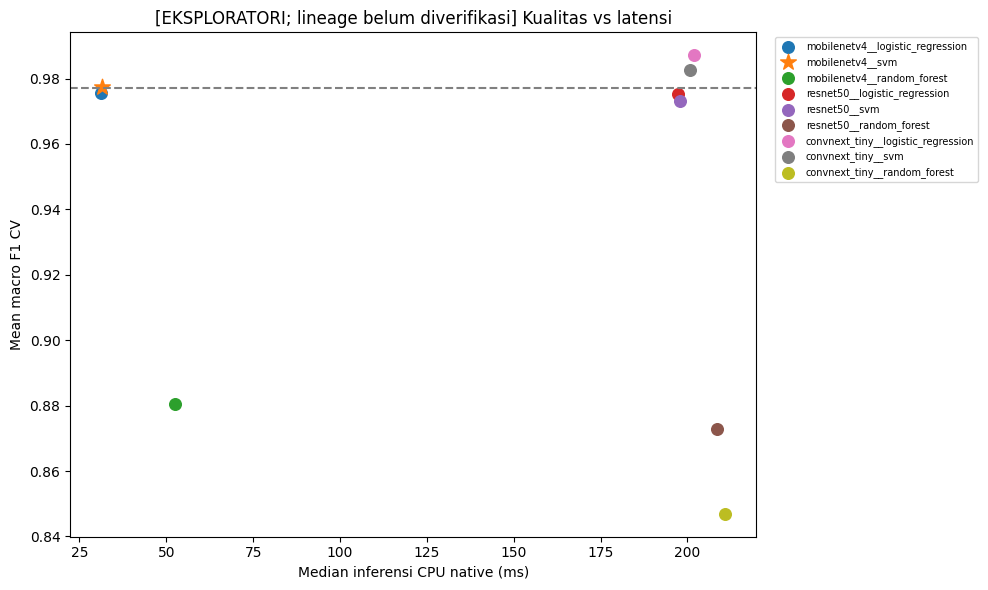

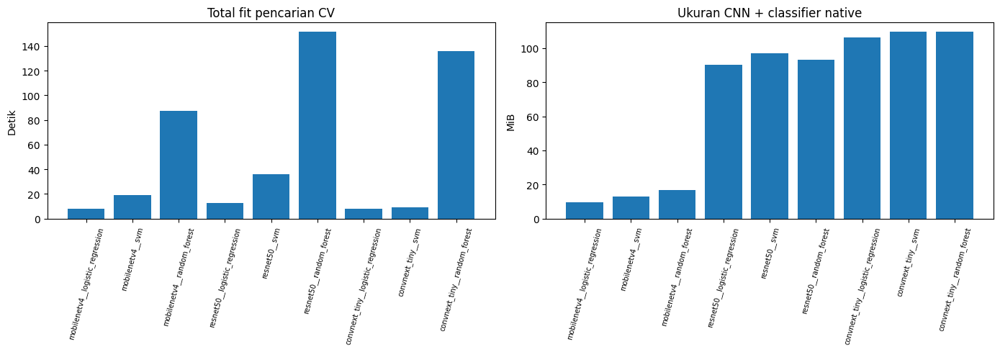

,identity,cnn,classifier,combo_id,best_params,mean_macro_f1,std_macro_f1,refit_seconds,total_search_fit_seconds,exploratory,median_ms,p95_ms,combined_bytes,runtime,quality_candidate
0,0a25ac69b5188a2f8adecd22cdc1c36e10419f90cdce87...,mobilenetv4,logistic_regression,mobilenetv4__logistic_regression,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.975522,0.014748,0.651665,8.171378,True,31.293081,72.503074,10244020,PyTorch CPU + sklearn; batch1; RF predict jobs1,False
1,72945b0c561c11d0511c8aadf638c9573fc1cd71a93c5f...,mobilenetv4,svm,mobilenetv4__svm,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.977305,0.016482,0.314759,18.847701,True,31.382173,82.453699,13744380,PyTorch CPU + sklearn; batch1; RF predict jobs1,True
2,2443adf98a25b66f2f289cb87db220f9d371a19584a874...,mobilenetv4,random_forest,mobilenetv4__random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.880467,0.041043,6.377422,87.607722,True,52.561505,104.717611,17439661,PyTorch CPU + sklearn; batch1; RF predict jobs1,False
3,dfcddde3e34dbaa5401b64f5dc9e92e732ffd7408ed2df...,resnet50,logistic_regression,resnet50__logistic_regression,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.975142,0.020050,1.336322,12.447775,True,197.414857,736.045431,94464308,PyTorch CPU + sklearn; batch1; RF predict jobs1,False
4,d9f2f9db58ed3f3fa11cebec862a3dd5d30cdb8c1b572c...,resnet50,svm,resnet50__svm,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.973040,0.021759,1.018557,35.725971,True,197.736553,721.880947,101812284,PyTorch CPU + sklearn; batch1; RF predict jobs1,False
5,5be2cad8cfb6efc7673babadee23dc5a6154e47fee933b...,resnet50,random_forest,resnet50__random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.872833,0.030093,10.395902,151.412558,True,208.609373,749.763108,97675885,PyTorch CPU + sklearn; batch1; RF predict jobs1,False
6,c93f73753dc684be6cd828e597957a1a24a82a6ff5320c...,convnext_tiny,logistic_regression,convnext_tiny__logistic_regression,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.987108,0.006839,0.459782,7.977588,True,201.874562,686.451141,111392372,PyTorch CPU + sklearn; batch1; RF predict jobs1,True
7,1d652d192a95787bf617398f5c485c3aa82df5d2c4768a...,convnext_tiny,svm,convnext_tiny__svm,"{'model__C': 10, 'model__class_weight': 'balan...",0.982477,0.013318,0.379162,9.121813,True,200.698733,668.227887,114850796,PyTorch CPU + sklearn; batch1; RF predict jobs1,True
8,b66f7357a7f799c87e18c711cfc1f0a543f385025f6318...,convnext_tiny,random_forest,convnext_tiny__random_forest,"{'model__class_weight': 'balanced', 'model__ma...",0.846937,0.037489,6.213950,135.930309,True,210.818775,785.865890,114799853,PyTorch CPU + sklearn; batch1; RF predict jobs1,False


{
  "identity": "72945b0c561c11d0511c8aadf638c9573fc1cd71a93c5f7a6f4a3d34d6ef3d5c",
  "cnn": "mobilenetv4",
  "classifier": "svm",
  "combo_id": "mobilenetv4__svm",
  "best_params": {
    "model__C": 0.1,
    "model__class_weight": "balanced",
    "model__gamma": "scale",
    "model__kernel": "linear"
  },
  "mean_macro_f1": 0.9773053597285515,
  "std_macro_f1": 0.01648160152395272,
  "refit_seconds": 0.31475910500012105,
  "total_search_fit_seconds": 18.84770110000136,
  "exploratory": true,
  "median_ms": 31.382173000110924,
  "p95_ms": 82.45369939968454,
  "combined_bytes": 13744380,
  "runtime": "PyTorch CPU + sklearn; batch1; RF predict jobs1",
  "quality_candidate": true,
  "selection_rule": "CV macroF1 within tolerance, then native CPU median latency, then bytes, then combo_id"
}


In [34]:
from kulitku_ml.benchmarking import benchmark
display(benchmark(run,splits))
print((run.out/'selection.json').read_text())


## 11. Test final kombinasi terpilih
Hanya pilihan yang sudah dikunci dievaluasi. Tidak tuning ulang atau mengganti pemenang berdasarkan test. Tersedia classification report, confusion matrix, metrik kelas, galeri salah, CI bootstrap kelompok dan grafik CV vs test. Bootstrap group tidak menjamin independensi antar pasien.


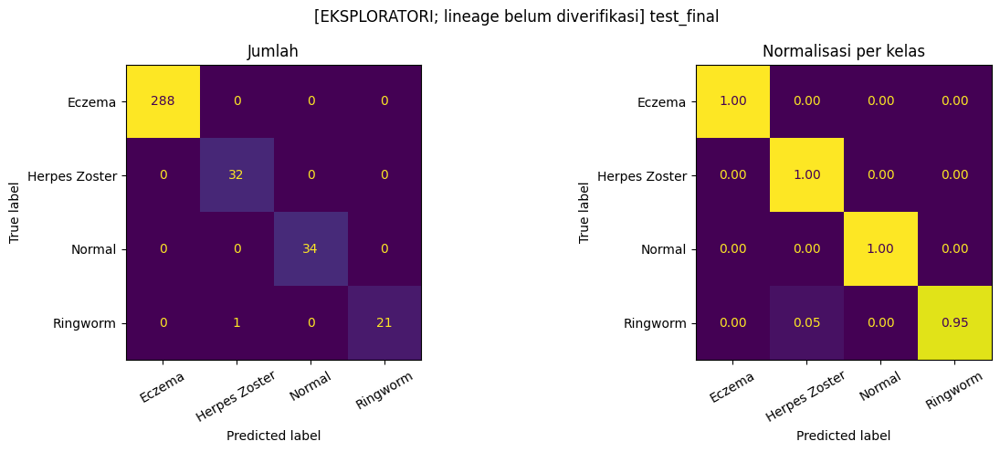

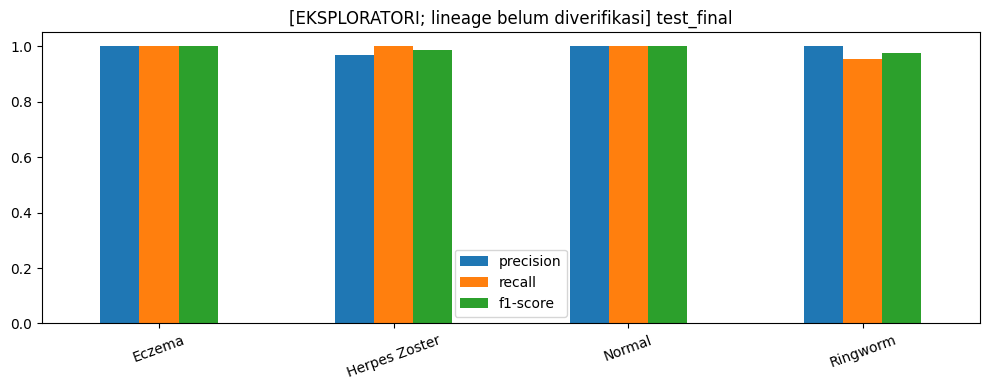

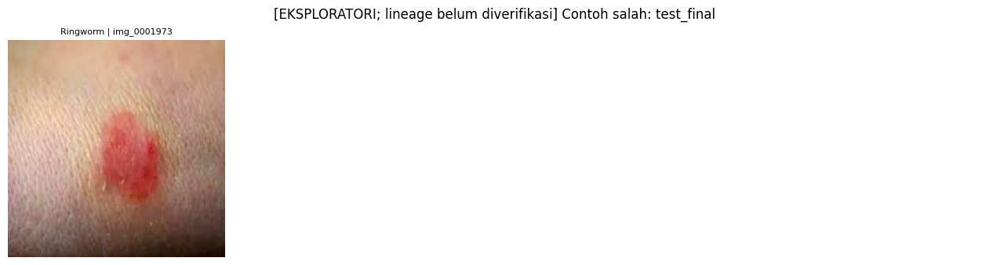

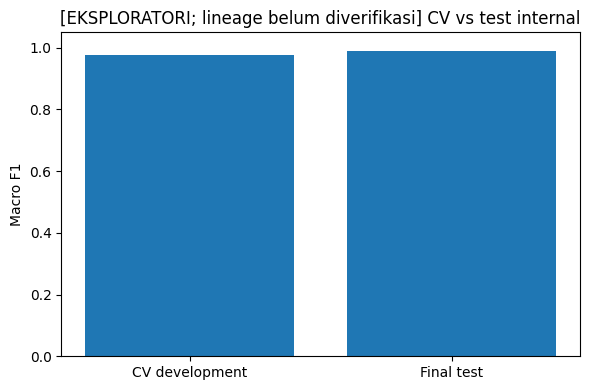

{'macro_f1': 0.9903398926654741,
 'accuracy': 0.9973404255319149,
 'macro_precision': 0.9924242424242424,
 'macro_recall': 0.9886363636363636}

In [35]:
from kulitku_ml.evaluation import final_test
selected=json.loads((run.out/'selection.json').read_text())
display(final_test(run,splits,selected['cnn'],selected['classifier']))


## Uji Coba pakai gambar sendiri


File: istockphoto-671737820-612x612.jpg


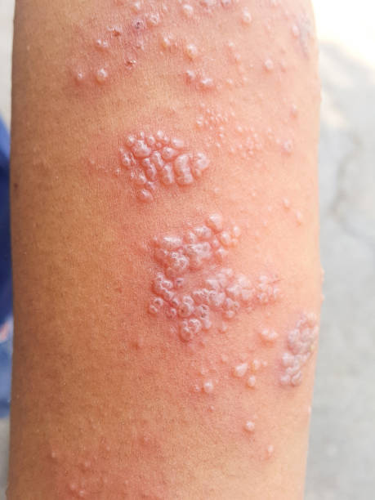

Prediksi: Herpes Zoster
Waktu proses: 147397.8 ms

Skor keputusan SVM — BUKAN persen confidence:
Herpes Zoster: 3.2211
Eczema: 2.1605
Ringworm: 1.1336
Normal: -0.2603

Confidence (%) belum tersedia. Model perlu dikalibrasi terlebih dahulu.


In [53]:
        prediction = pipeline.predict(feature)[0]
        label = run.c['classes'][int(prediction)]

        elapsed_ms = (time.perf_counter() - start) * 1000

        print(f'\nFile: {filename}')
        preview = image.copy()
        preview.thumbnail((500, 500))
        display(preview)

        print('Prediksi:', label)
        print(f'Waktu proses: {elapsed_ms:.1f} ms')

        # Urutan kelas mengikuti classifier, bukan urutan skor terbesar.
        class_ids = pipeline.classes_

        if hasattr(pipeline, 'predict_proba'):
            probabilities = pipeline.predict_proba(feature)[0]

            print('\nProbabilitas model per kelas:')
            for position in np.argsort(probabilities)[::-1]:
                class_label = run.c['classes'][int(class_ids[position])]
                print(
                    f'{class_label}: '
                    f'{probabilities[position] * 100:.2f}%'
                )

        elif hasattr(pipeline, 'decision_function'):
            scores = np.asarray(
                pipeline.decision_function(feature)
            )

            # Empat kelas: pastikan skor memakai format one-vs-rest.
            estimator = pipeline.named_steps['model']
            score_shape = getattr(
                estimator, 'decision_function_shape', 'ovr'
            )

            if (
                score_shape == 'ovr'
                and scores.shape == (1, len(class_ids))
            ):
                scores = scores[0]

                print('\nSkor keputusan SVM — BUKAN persen confidence:')
                for position in np.argsort(scores)[::-1]:
                    class_label = run.c['classes'][
                        int(class_ids[position])
                    ]
                    print(f'{class_label}: {scores[position]:.4f}')

                print(
                    '\nConfidence (%) belum tersedia. '
                    'Model perlu dikalibrasi terlebih dahulu.'
                )
            else:
                print(
                    '\nSkor SVM bukan satu skor per kelas; '
                    'confidence (%) belum tersedia.'
                )
        else:
            print('\nModel hanya menyediakan label prediksi.')

## 12. Ekspor ONNX dan parity check
Ekspor CNN dan pipeline scaler/classifier. Sklearn converter mendukung classifier yang digunakan, tetapi numerik harus diverifikasi. Parity memakai gambar development, membandingkan fitur dan label native vs ONNX. Jika gagal, proses berhenti dan tidak membuat release siap inferensi.

labels.json dan preprocessing.json benar-benar dikonsumsi oleh Predictor pada bagian 13. Tidak ada persentase kepastian medis yang diklaim. Preprocessing masih di luar grafik ONNX; kedua model ONNX menerima tensor/fitur, bukan JPEG.


In [ ]:
from kulitku_ml.export import export_selected
release_dir=export_selected(run,splits)
print('Paket:',release_dir)


## 13. Uji paket inferensi hasil ekspor
Predictor membaca release, checksum, label, dan konfigurasi preprocessing, lalu menjalankan kedua file ONNX. Ini modul inferensi untuk calon integrasi FastAPI, bukan layanan FastAPI/Flutter/Supabase lengkap. Waktu satu panggilan ini bukan benchmark aplikasi yang mencakup upload/jaringan.


In [ ]:
from kulitku_ml.inference import Predictor
predictor=Predictor(release_dir,threads=cfg['benchmark']['threads'])
example=splits[splits.partition.eq('development')].iloc[0]
print(predictor.predict(run.root/example.relative_path))
print('Selesai. Semua hasil:',run.out)


## File yang benar-benar dipakai
| Bagian | Pemanggil |
|---|---|
| configs/experiment.json | load_config di bagian 3 |
| src/kulitku_ml/config.py | konfigurasi, folder otomatis, penyimpanan output |
| data.py dan eda.py | bagian 4–5 |
| cleaning.py | bagian 5 |
| splitting.py | bagian 6 dan indeks CV pada training |
| preprocessing.py dan features.py | bagian 7, benchmarking, export, inferensi |
| training.py dan evaluation.py | bagian 8–9 dan 11 |
| benchmarking.py | bagian 10 |
| export.py dan inference.py | bagian 12–13 |

Folder Drive otomatis: grafik/, tabel/, features/<cnn>/, models/<cnn>/<classifier>/, onnx/<pilihan>/. CSV cleaning dan split tetap diperlukan untuk keterlacakan, tetapi tidak ada folder manifests terpisah. Notebook tidak membuat salinan dataset hasil cleaning; kode membaca daftar gambar yang dipertahankan.

Keluaran adalah riset skrining awal, bukan diagnosis atau validasi klinis. Semua keterbatasan lineage/dataset tetap berlaku setelah export.
